# Datos Faltantes

In [1]:
# Importar librerías necesarias
import pandas as pd
import numpy as np
from sklearn.datasets import load_diabetes
from sklearn.impute import SimpleImputer, KNNImputer
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
# Cargar el conjunto de datos
diabetes = load_diabetes(as_frame=True)
data = diabetes.data
data['target'] = diabetes.target

In [3]:
data.sample(10)

,age,sex,bmi,bp,s1,s2,s3,s4,s5,s6,target
201,-0.034575,0.050680,-0.055785,-0.015999,-0.009825,-0.007890,0.037595,-0.039493,-0.052963,0.027917,39.0
299,0.038076,0.050680,-0.013751,-0.015999,-0.035968,-0.021982,-0.013948,-0.002592,-0.025953,-0.001078,83.0
207,0.009016,-0.044642,0.045529,0.028758,0.012191,-0.013840,0.026550,-0.039493,0.046133,0.036201,202.0
312,-0.074533,-0.044642,-0.023451,-0.005670,-0.020832,-0.014153,0.015505,-0.039493,-0.038460,-0.030072,144.0
155,-0.027310,0.050680,0.060618,0.049415,0.085116,0.086368,-0.002903,0.034309,0.037811,0.048628,186.0
251,-0.052738,0.050680,0.098342,0.087287,0.060349,0.048790,-0.058127,0.108111,0.084492,0.040343,243.0
117,0.059871,-0.044642,-0.021295,0.087287,0.045213,0.031567,-0.047082,0.071210,0.079122,0.135612,281.0
103,0.059871,0.050680,0.041218,0.011544,0.041086,0.070710,-0.036038,0.034309,-0.010903,-0.030072,198.0
49,-0.041840,0.050680,0.014272,-0.005670,-0.012577,0.006202,-0.072854,0.071210,0.035459,-0.013504,142.0
198,-0.052738,-0.044642,0.054152,-0.026328,-0.055231,-0.033881,-0.013948,-0.039493,-0.074093,-0.059067,142.0


In [4]:
# Simular valores faltantes
np.random.seed(42)
data.loc[data.sample(frac=0.1).index, 'bmi'] = np.nan
data.loc[data.sample(frac=0.1).index, 'bp'] = np.nan

# Ejercicios
Contesta las siguientes preguntas. Para cada pregunta, deberás escribir código que demostrará cómo llegaste al resultado:

### 1. ¿Cuántos valores faltantes hay en cada columna?**

In [5]:

# Contar los valores faltantes por columna
print(data.isnull().sum())


age        0
sex        0
bmi       44
bp        44
s1         0
s2         0
s3         0
s4         0
s5         0
s6         0
target     0
dtype: int64


### 2. Utiliza imputación simple (media) para llenar los valores faltantes de la columna 'bmi'.

In [6]:

# Crear una copia de los datos originales
data_mean = data.copy()

# Crear el imputador con la estrategia de media
imputer_mean = SimpleImputer(strategy='mean')

# Imputar los valores faltantes de bmi
data_mean[['bmi']] = imputer_mean.fit_transform(data_mean[['bmi']])

# Comprobar si quedan valores faltantes
print("Valores faltantes en bmi después de la imputación:")
print(data_mean['bmi'].isnull().sum())

# Mostrar la media utilizada
print("Media de bmi:", imputer_mean.statistics_[0])


Valores faltantes en bmi después de la imputación:
0
Media de bmi: -0.00020486982495318998


### 3. Utiliza KNNImputer para imputar valores en las columnas 'bmi' y 'bp'. Compara los resultados con los de la imputación simple.

In [7]:

# Crear una copia de los datos originales
data_knn = data.copy()

# Crear el imputador KNN con 5 vecinos
imputer_knn = KNNImputer(n_neighbors=5)

# Imputar bmi y bp
data_knn[['bmi', 'bp']] = imputer_knn.fit_transform(
    data_knn[['bmi', 'bp']]
)

# Comprobar los valores faltantes
print("Valores faltantes después de KNN:")
print(data_knn[['bmi', 'bp']].isnull().sum())

# Comparar los resultados de bmi
comparacion = pd.DataFrame({
    'Original': data['bmi'],
    'Imputacion_media': data_mean['bmi'],
    'Imputacion_KNN': data_knn['bmi']
})

# Mostrar algunas filas donde bmi tenía valores faltantes
indices_faltantes = data[data['bmi'].isnull()].index

print("\nComparación de las primeras 10 imputaciones:")
print(comparacion.loc[indices_faltantes].head(10))

# Comparar las medias y desviaciones estándar
print("\nEstadísticas de bmi:")
print(comparacion[['Imputacion_media', 'Imputacion_KNN']].agg(
    ['mean', 'std']
))


Valores faltantes después de KNN:
bmi    0
bp     0
dtype: int64

Comparación de las primeras 10 imputaciones:
    Original  Imputacion_media  Imputacion_KNN
9        NaN         -0.000205       -0.025822
30       NaN         -0.000205       -0.000205
39       NaN         -0.000205       -0.000205
55       NaN         -0.000205        0.017075
70       NaN         -0.000205       -0.022158
72       NaN         -0.000205       -0.022158
73       NaN         -0.000205       -0.004481
75       NaN         -0.000205       -0.031211
76       NaN         -0.000205        0.025913
78       NaN         -0.000205        0.006728

Estadísticas de bmi:
      Imputacion_media  Imputacion_KNN
mean         -0.000205       -0.000164
std           0.044583        0.045148


### 4. Genera un histograma comparando los datos antes y después de la imputación en la columna 'bmi'.

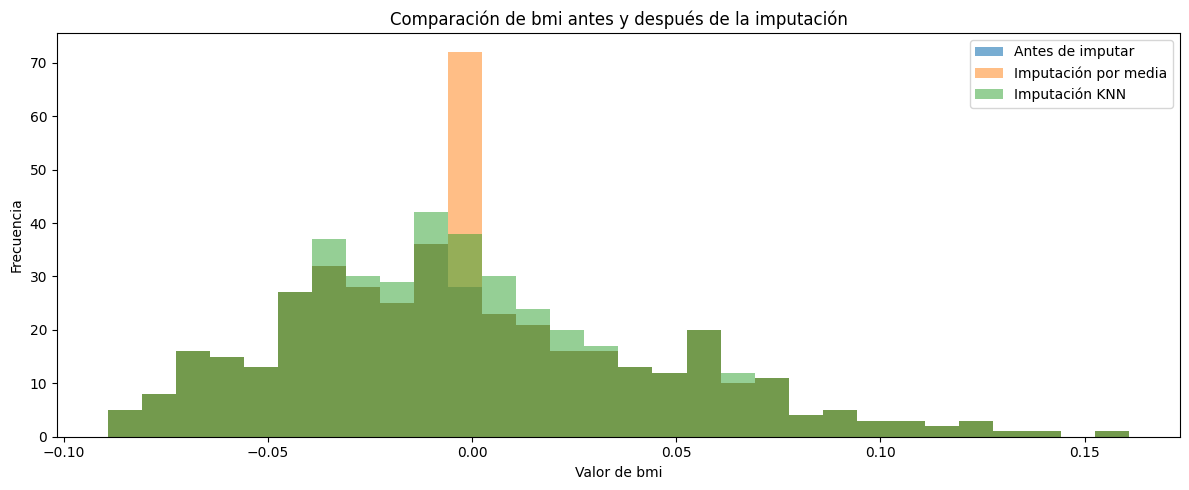

In [8]:

# Crear la figura con tres histogramas
plt.figure(figsize=(12, 5))

# Datos originales, excluyendo los valores faltantes
plt.hist(
    data['bmi'].dropna(),
    bins=30,
    alpha=0.6,
    label='Antes de imputar'
)

# Datos imputados con la media
plt.hist(
    data_mean['bmi'],
    bins=30,
    alpha=0.5,
    label='Imputación por media'
)

# Datos imputados con KNN
plt.hist(
    data_knn['bmi'],
    bins=30,
    alpha=0.5,
    label='Imputación KNN'
)

plt.title('Comparación de bmi antes y después de la imputación')
plt.xlabel('Valor de bmi')
plt.ylabel('Frecuencia')
plt.legend()
plt.tight_layout()
plt.show()
